# Exploratory Data Analysis

## 1. Data Loading and Overview

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
project_root = Path.cwd().parent

df = pd.read_csv(
    project_root / "data" / "raw" / "train.csv"
)

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.drop(columns=['Id'],inplace=True)
df.shape

(1460, 80)

## 2. Initial Data Exploration

Before examining individual variables, I first take a brief look at the overall structure of the dataset. The predictors are divided into numerical and categorical features, as these groups will require different approaches during further exploration and preprocessing.

In [4]:
numerical_features = [
    var for var in df.select_dtypes(include=np.number).columns
    if var not in ['SalePrice', 'MSSubClass']
]

categorical_features = (
    df.select_dtypes(exclude=np.number).columns.tolist()
    + ['MSSubClass']
)

print(f'Numerical features: {len(numerical_features)}')
print(f'Categorical features: {len(categorical_features)}')
print(f'Total predictors: {len(numerical_features) + len(categorical_features)}')

Numerical features: 35
Categorical features: 44
Total predictors: 79


### 2.1 Missing Values Overview

In [5]:
missing_ratio = (
    df.isnull()
        .mean()
        .sort_values(ascending=False)
)

missing_ratio = missing_ratio[missing_ratio > 0]

print(f'Features with missing values: {len(missing_ratio)}')
print(f'Features without missing values: {df.shape[1] - len(missing_ratio)}')

Features with missing values: 19
Features without missing values: 61


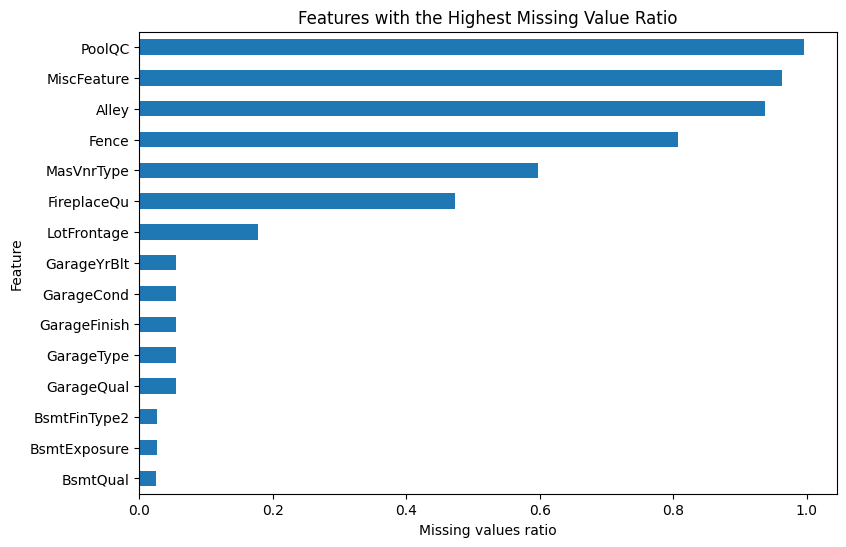

In [6]:
plt.figure(figsize=(9, 6))

missing_ratio.head(15).sort_values().plot(kind='barh')

plt.xlabel('Missing values ratio')
plt.ylabel('Feature')
plt.title('Features with the Highest Missing Value Ratio')

plt.show()

### 2.2 Correlation Overview

To obtain a quick overview of the numerical relationships in the dataset, I examine the variables most strongly correlated with `SalePrice`. This is only an initial exploratory step — a more comprehensive feature selection procedure will be performed later using multiple statistical measures and redundancy analysis.

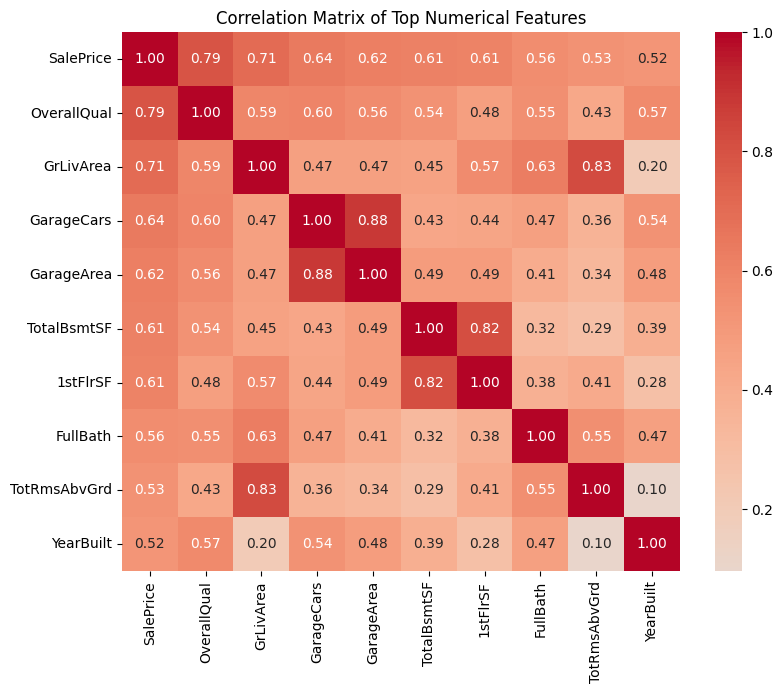

In [24]:
correlations = (
    df[numerical_features + ["SalePrice"]]
    .corr()["SalePrice"]
    .abs()
    .sort_values(ascending=False)
)

top_corr_features = correlations.head(10).index

plt.figure(figsize=(9, 7))

sns.heatmap(
    df[top_corr_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Top Numerical Features")
plt.show()

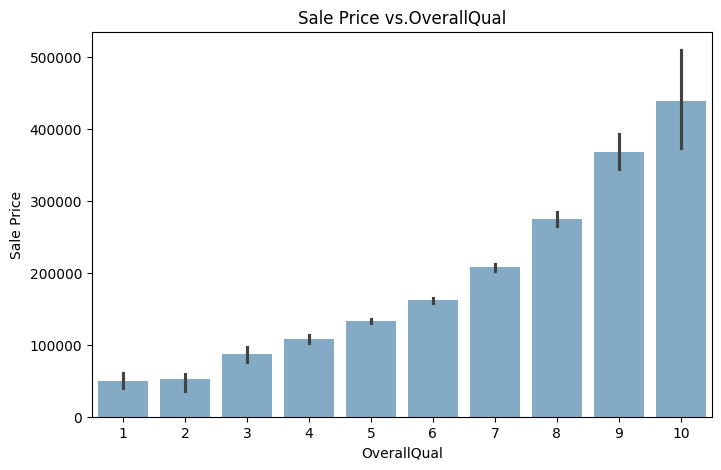

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='OverallQual',
    y='SalePrice',
    alpha=0.6
)

plt.title('Sale Price vs.OverallQual')
plt.xlabel('OverallQual')
plt.ylabel('Sale Price')

plt.show()

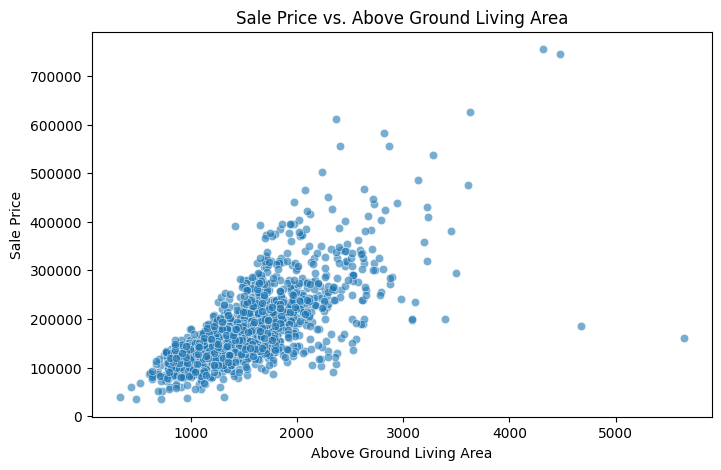

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice',
    alpha=0.6
)

plt.title('Sale Price vs. Above Ground Living Area')
plt.xlabel('Above Ground Living Area')
plt.ylabel('Sale Price')

plt.show()

Initial observations: OverallQual and GrLivArea show the strongest linear relationships with SalePrice among the selected numerical features. The scatter plot confirms a clear positive relationship between living area and sale price, while also showing several atypical observations. Strong correlations between some predictors also suggest possible feature redundancy, which will be investigated later during feature selection.

## 3. Target Variable Analysis

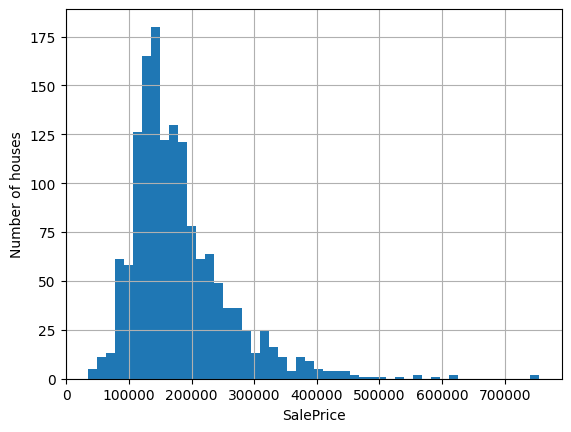

In [9]:
df['SalePrice'].hist(bins=50)
plt.ylabel('Number of houses')
plt.xlabel('SalePrice')
plt.show()

The target variable (`SalePrice`) exhibits a right-skewed distribution. A logarithmic transformation will be examined to reduce skewness and obtain a more symmetric distribution.

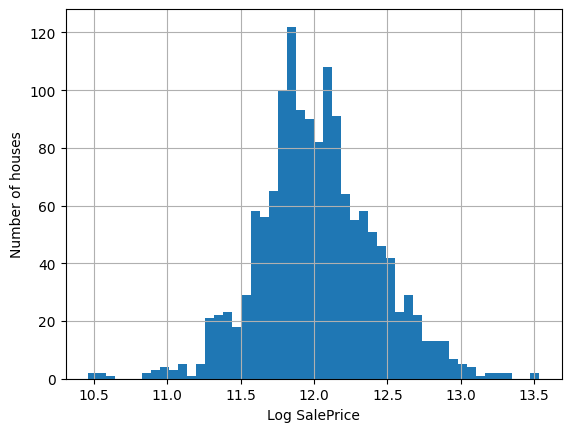

In [10]:
np.log(df['SalePrice']).hist(bins=50)
plt.ylabel('Number of houses')
plt.xlabel('Log SalePrice')
plt.show()

After applying the logarithmic transformation, the distribution becomes more symmetric and closer to a bell-shaped distribution.

## 4. Missing Values Analysis

In [11]:
vars_with_na = [var for var in df.columns if df[var].isna().sum()>0]

missing_ratio = df[vars_with_na].isnull().mean().sort_values(ascending=False)
missing_ratio.name=""
missing_ratio

PoolQC          0.995205
MiscFeature     0.963014
Alley           0.937671
Fence           0.807534
MasVnrType      0.597260
FireplaceQu     0.472603
LotFrontage     0.177397
GarageType      0.055479
GarageYrBlt     0.055479
GarageFinish    0.055479
GarageQual      0.055479
GarageCond      0.055479
BsmtExposure    0.026027
BsmtFinType2    0.026027
BsmtQual        0.025342
BsmtCond        0.025342
BsmtFinType1    0.025342
MasVnrArea      0.005479
Electrical      0.000685
Name: , dtype: float64

Missing values are unevenly distributed across features. A small number of variables contain a substantial proportion of missing observations, while most affected features have relatively few missing values.

Let's examine how missing values are associated with the target variable.

In [12]:
def analyze_missing_value(df, var):
  df = df.copy()

  df[var] = np.where(df[var].isnull(),1,0)

  tmp = df.groupby(var)['SalePrice'].agg(['mean', 'std'])

  tmp.plot(kind='barh', y='mean', xerr='std', title='Sales Price', legend=False)

  plt.show()

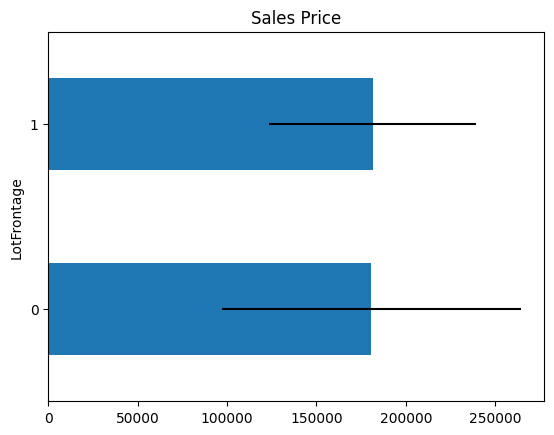

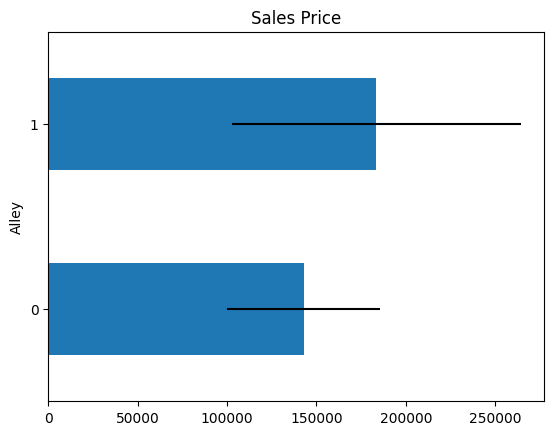

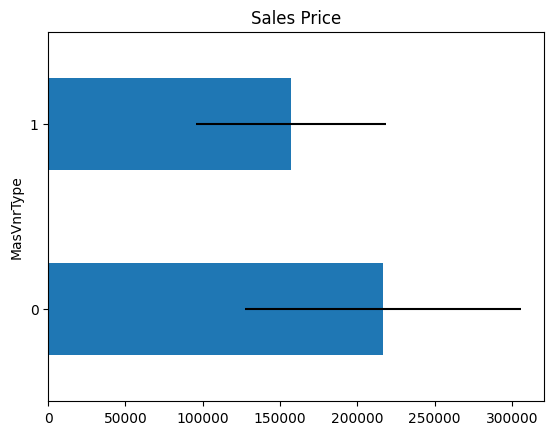

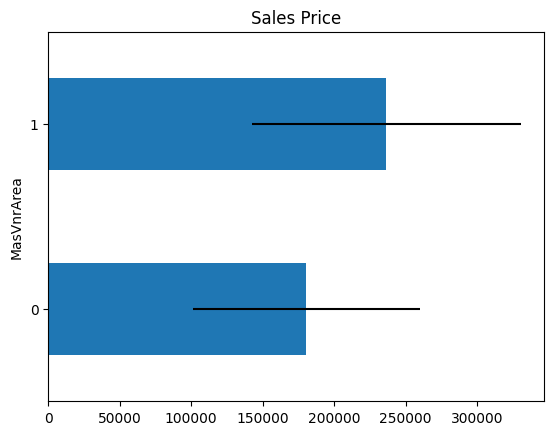

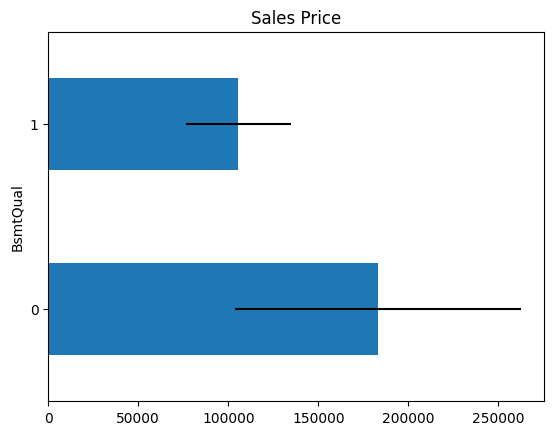

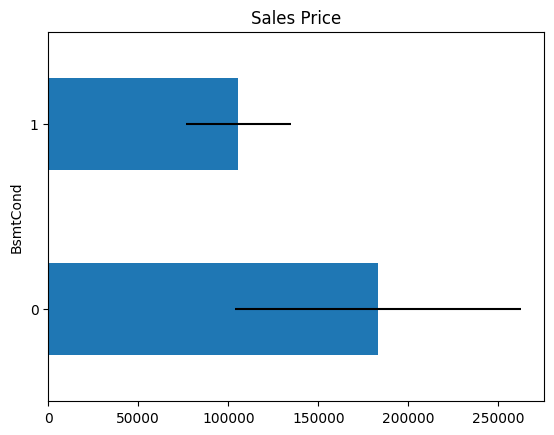

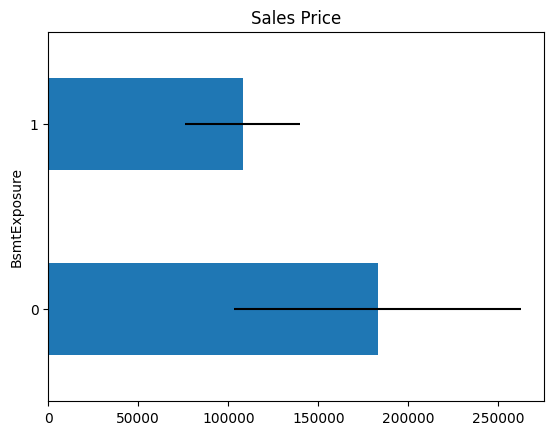

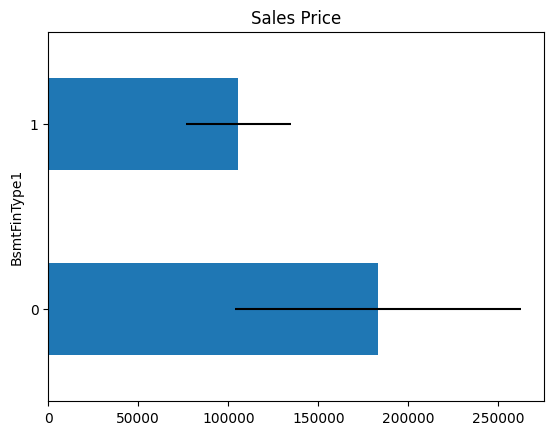

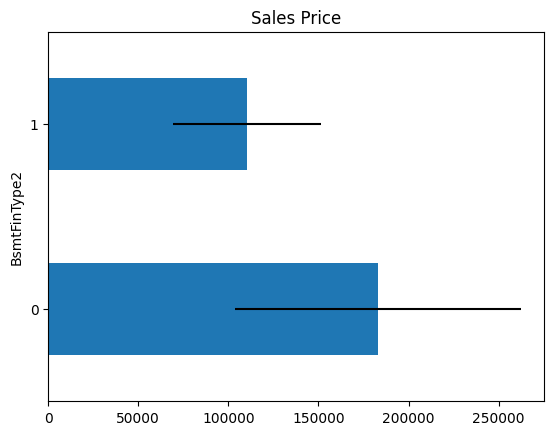

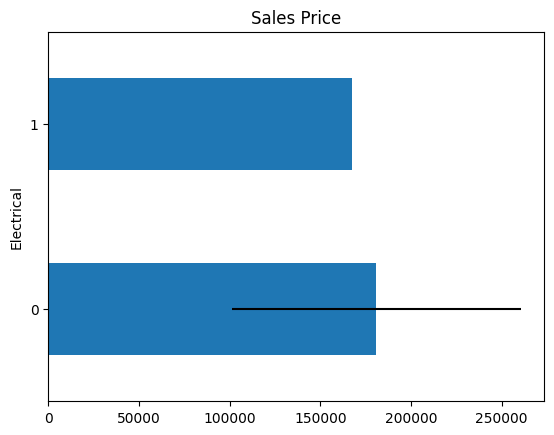

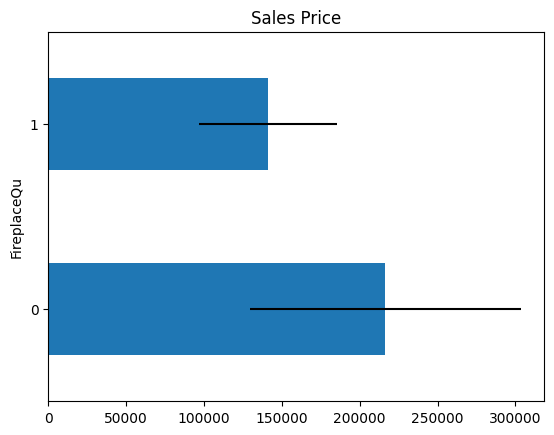

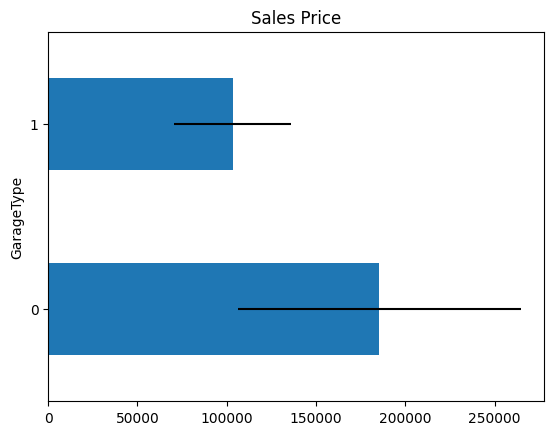

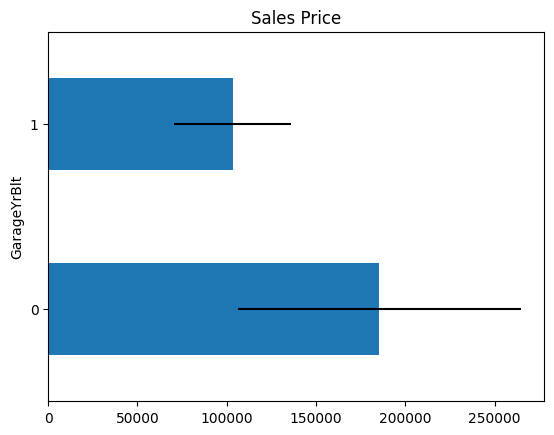

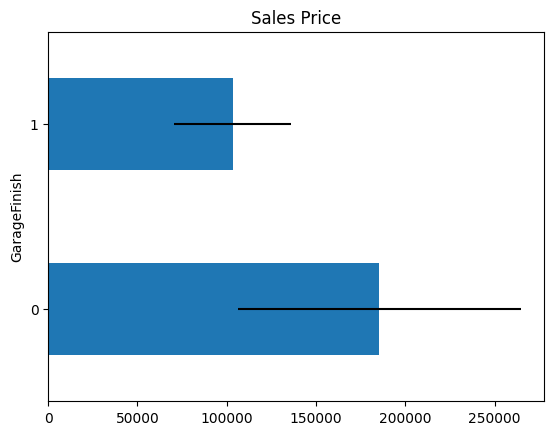

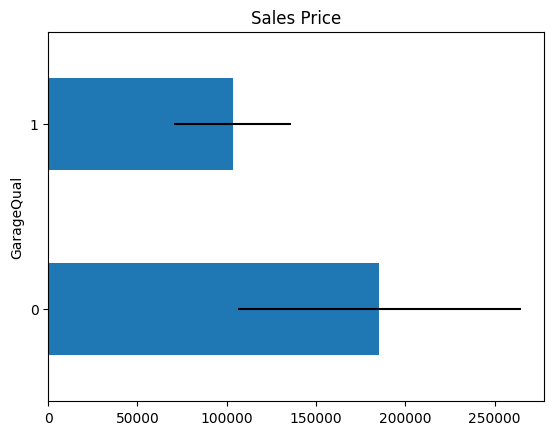

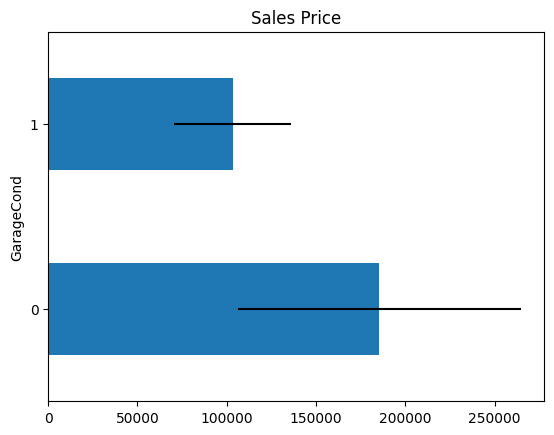

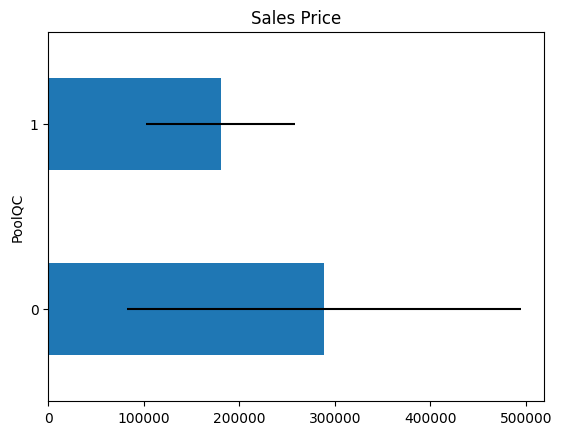

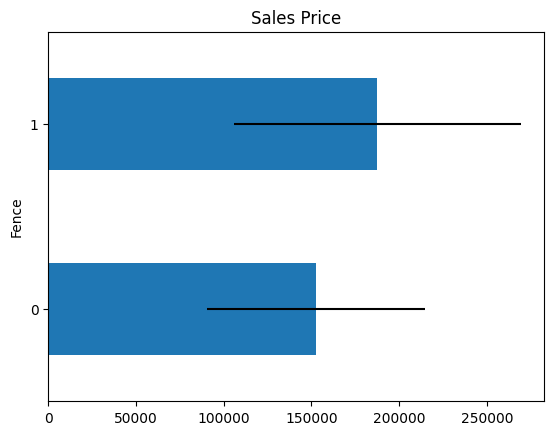

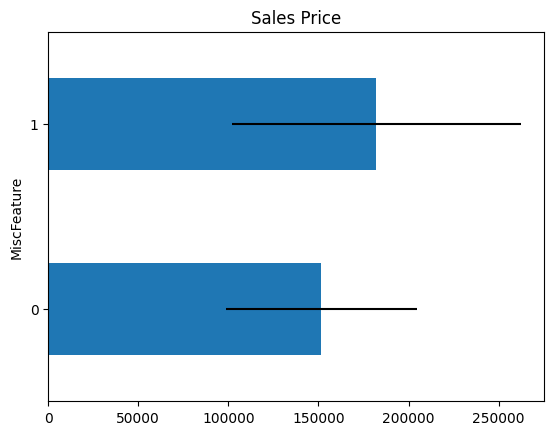

In [13]:
for var in vars_with_na:
  analyze_missing_value(df, var)

For several features, the average sale price differs between properties with missing and non-missing values. This suggests that missingness may contain useful predictive information.

However, these differences do not necessarily imply that missing-value indicators will improve model performance. Their potential usefulness will be evaluated during Feature Engineering and model validation.

## 5. Numerical Features Analysis

### 5.1 Discrete Features

In [14]:
num_vars = [var for var in df.columns if df[var].dtypes!='O' and var!='SalePrice' and var!='MSSubClass']
df[num_vars].head()

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,...,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
0,65.0,8450,7,5,2003,2003,196.0,706,0,150,...,548,0,61,0,0,0,0,0,2,2008
1,80.0,9600,6,8,1976,1976,0.0,978,0,284,...,460,298,0,0,0,0,0,0,5,2007
2,68.0,11250,7,5,2001,2002,162.0,486,0,434,...,608,0,42,0,0,0,0,0,9,2008
3,60.0,9550,7,5,1915,1970,0.0,216,0,540,...,642,0,35,272,0,0,0,0,2,2006
4,84.0,14260,8,5,2000,2000,350.0,655,0,490,...,836,192,84,0,0,0,0,0,12,2008


In [27]:
discrete_vars = [var for var in num_vars if len(df[var].unique())<20 and var not in ['MSSubClass', 'YearBuilt', 'YearRemodAdd', 'YrSold', 'GarageYrBlt']]
df[discrete_vars].head()

,OverallQual,OverallCond,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageCars,PoolArea,MoSold
0,7,5,1,0,2,1,3,1,8,0,2,0,2
1,6,8,0,1,2,0,3,1,6,1,2,0,5
2,7,5,1,0,2,1,3,1,6,1,2,0,9
3,7,5,1,0,1,0,3,1,7,1,3,0,2
4,8,5,1,0,2,1,4,1,9,1,3,0,12


These discrete variables mainly represent property quality or condition ratings (e.g., `OverallQual`, `OverallCond`) and counts of specific property characteristics (e.g., `FullBath`, `GarageCars`, `KitchenAbvGr`).

For some of these variables, higher values may be associated with higher sale prices. The following plots will help examine these relationships.

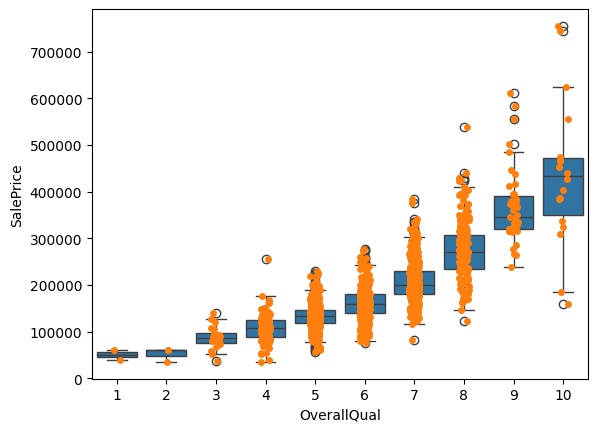

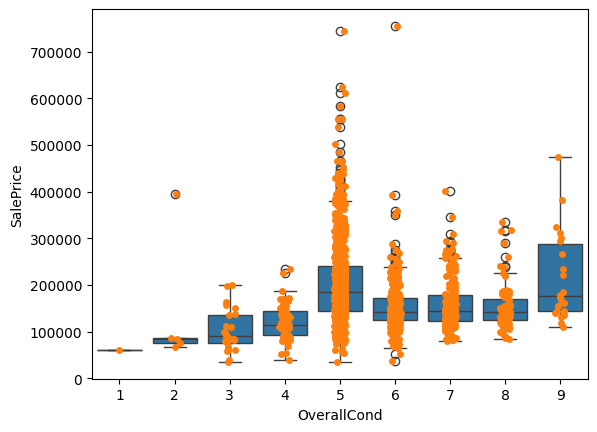

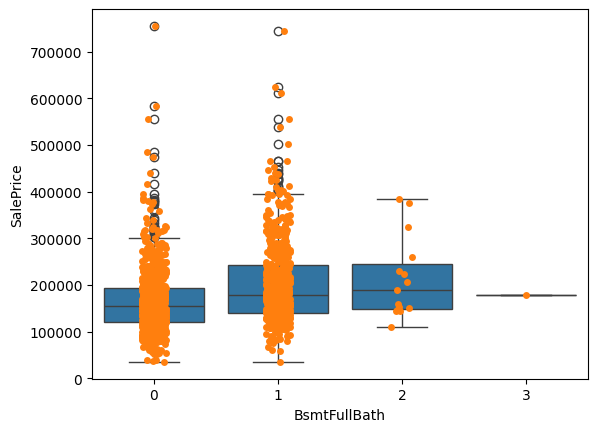

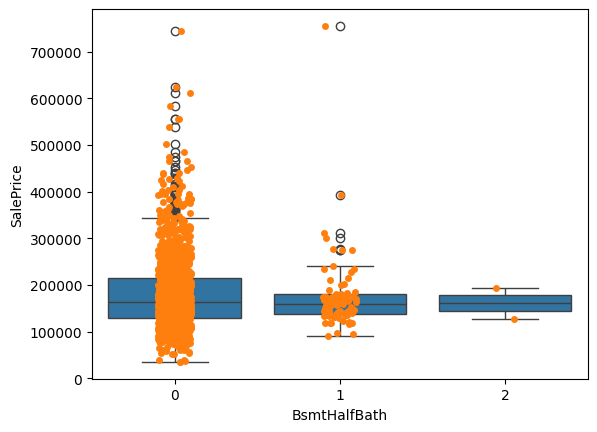

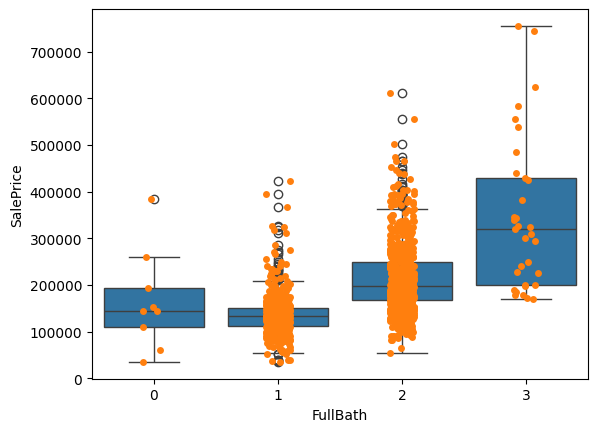

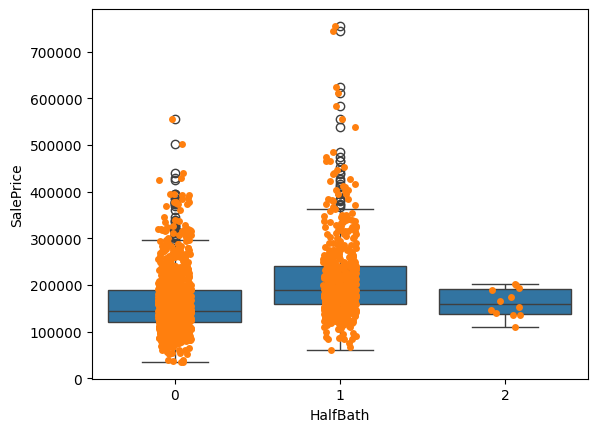

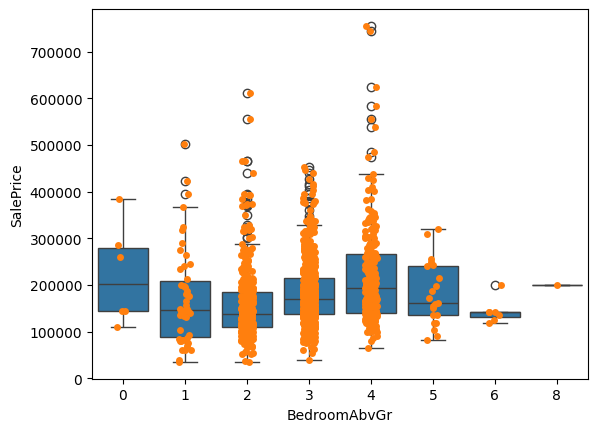

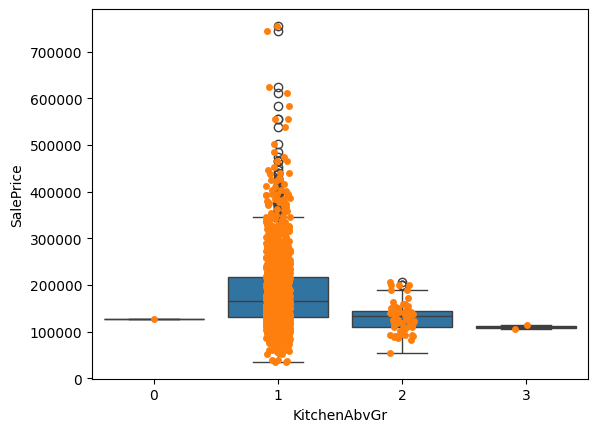

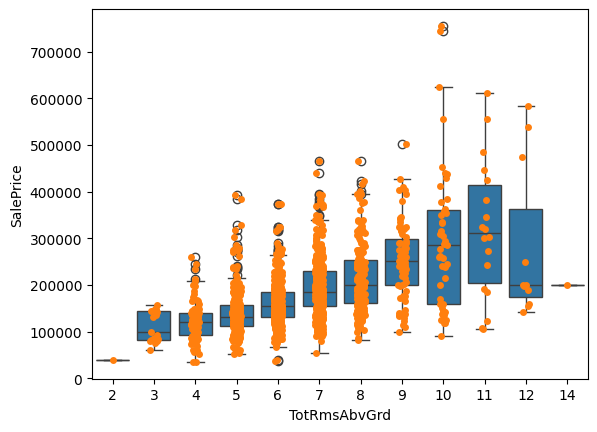

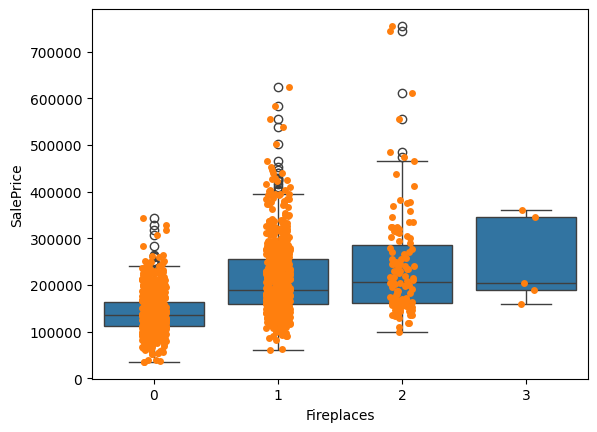

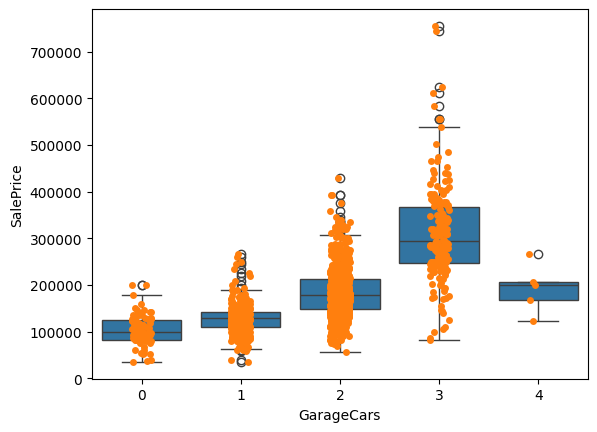

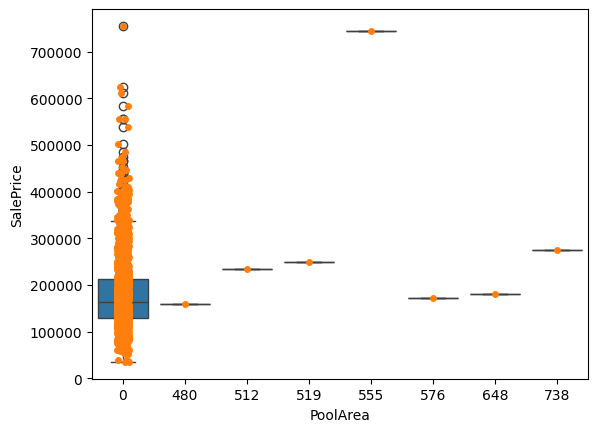

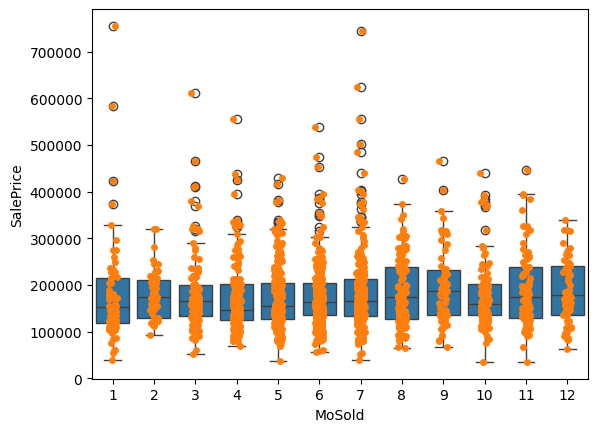

In [16]:
for var in discrete_vars:
  sns.boxplot(data=df, x=var, y='SalePrice')
  sns.stripplot(x=var, y='SalePrice', data=df)

  plt.show()

Several discrete features, particularly `OverallQual`, `FullBath`, `GarageCars`, and `TotRmsAbvGrd`, show a generally positive relationship with `SalePrice`.

For other variables, the relationship is less apparent or non-monotonic. However, this does not necessarily mean that they lack predictive value, as they may still contribute useful information through interactions with other features.

Their predictive usefulness will be assessed during model training and feature selection.

### 5.2 Continuous Features

In [28]:
cont_vars = [var for var in num_vars if var not in discrete_vars and var not in ['MSSubClass', 'YearBuilt', 'YearRemodAdd', 'YrSold', 'GarageYrBlt']]
df[cont_vars].head()

,LotFrontage,LotArea,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,MiscVal
0,65.0,8450,196.0,706,0,150,856,856,854,0,1710,548,0,61,0,0,0,0
1,80.0,9600,0.0,978,0,284,1262,1262,0,0,1262,460,298,0,0,0,0,0
2,68.0,11250,162.0,486,0,434,920,920,866,0,1786,608,0,42,0,0,0,0
3,60.0,9550,0.0,216,0,540,756,961,756,0,1717,642,0,35,272,0,0,0
4,84.0,14260,350.0,655,0,490,1145,1145,1053,0,2198,836,192,84,0,0,0,0


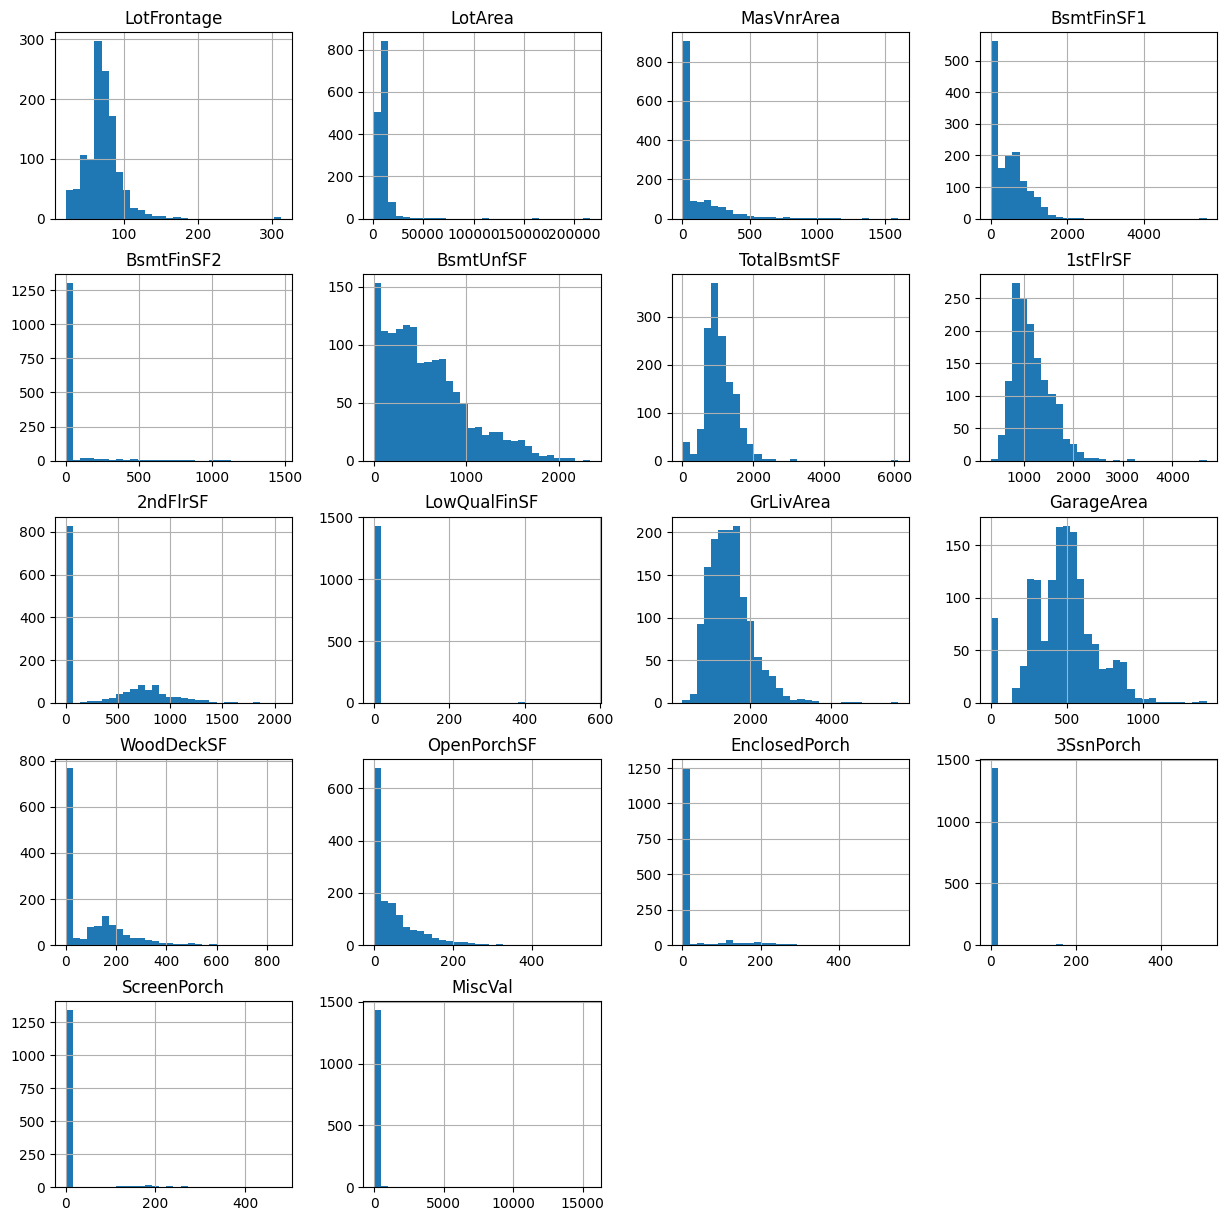

In [18]:
df[cont_vars].hist(bins=30, figsize=(15,15))
plt.show()

**Observations**

Most continuous features exhibit right-skewed distributions, with a relatively small number of observations having exceptionally high values. This is particularly noticeable for variables such as `LotArea`, `MasVnrArea`, `BsmtFinSF1`, and `GrLivArea`.

Several features, including `BsmtFinSF2`, `LowQualFinSF`, `3SsnPorch`, and `ScreenPorch`, contain a large proportion of zero values, indicating that many properties do not have these particular characteristics.

These observations suggest that some numerical features may benefit from transformations aimed at reducing skewness. The effects of such transformations will be examined in the following section.

### 5.3 Transformation Analysis

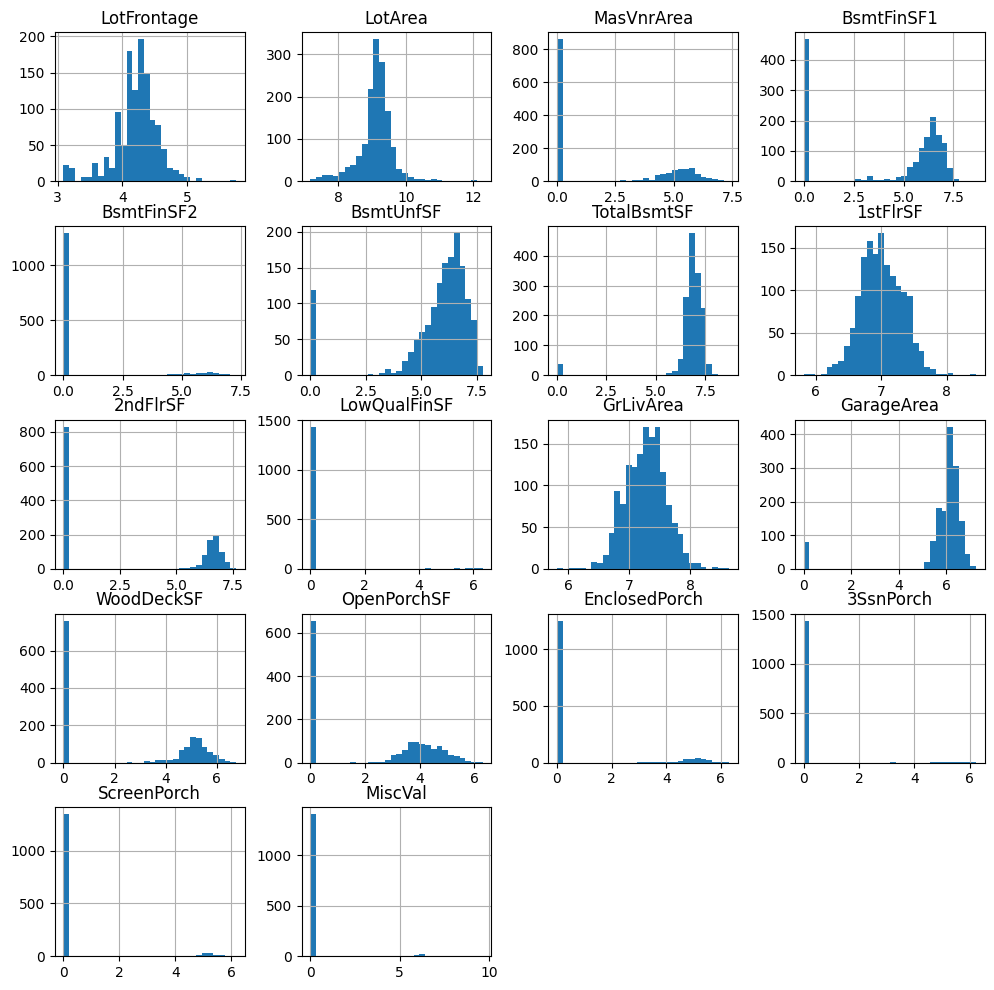

In [19]:
tmp = df.copy()
for var in cont_vars:
  tmp[var] = np.log1p(tmp[var])

tmp[cont_vars].hist(bins=30, figsize=(12,12))
plt.show()


The logarithmic transformation reduces positive skewness for several continuous variables, particularly LotArea, 1stFlrSF, and GrLivArea, producing more symmetric distributions.

However, the transformation is less effective for features with a large proportion of zero values, such as BsmtFinSF2, LowQualFinSF, and 3SsnPorch. These variables remain heavily concentrated at zero even after transformation.

Additionally, some features exhibit distinct groups of observations or unusual distribution patterns after transformation, suggesting that alternative approaches may be worth exploring.

Therefore, logarithmic transformation should be considered selectively rather than applied to all continuous features.

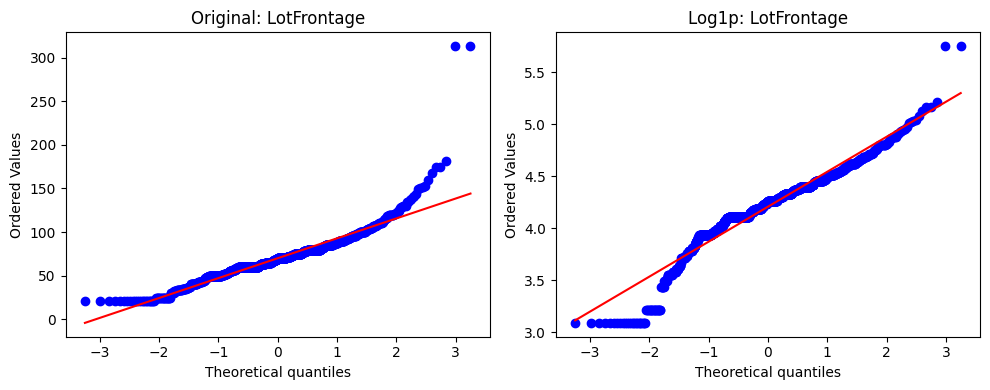

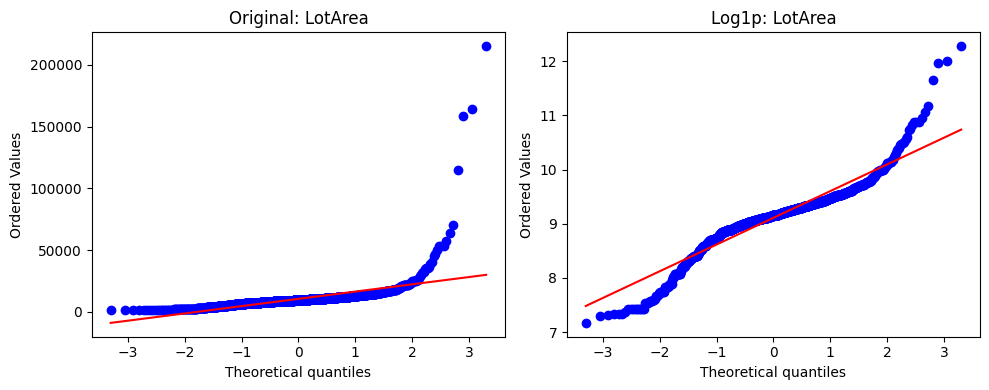

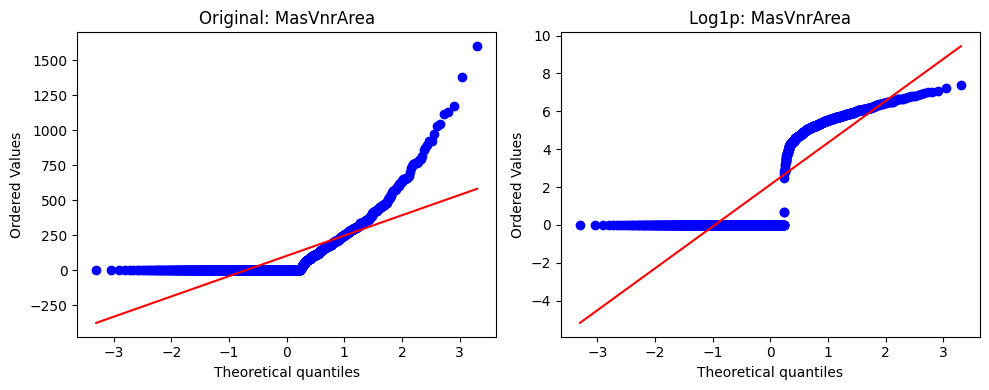

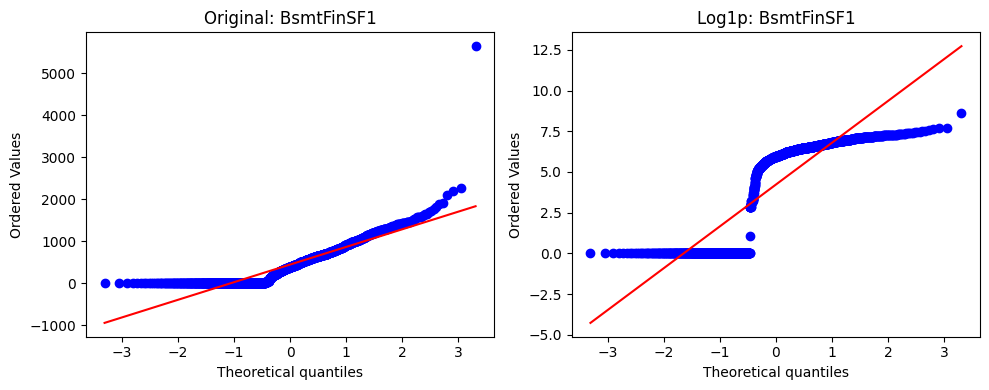

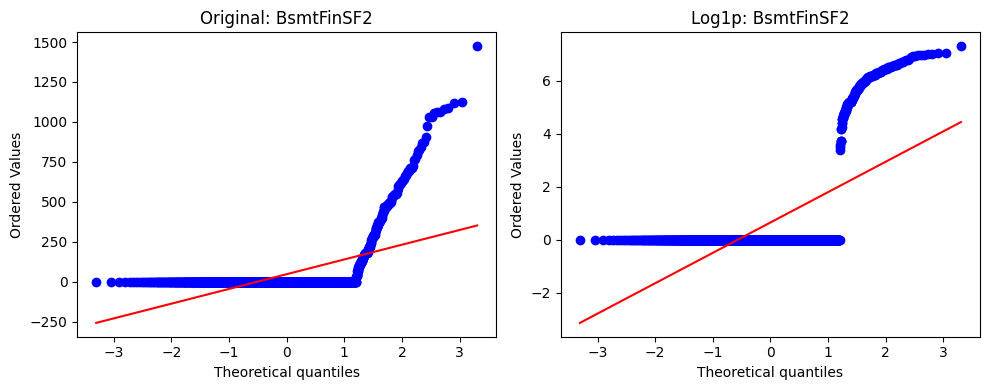

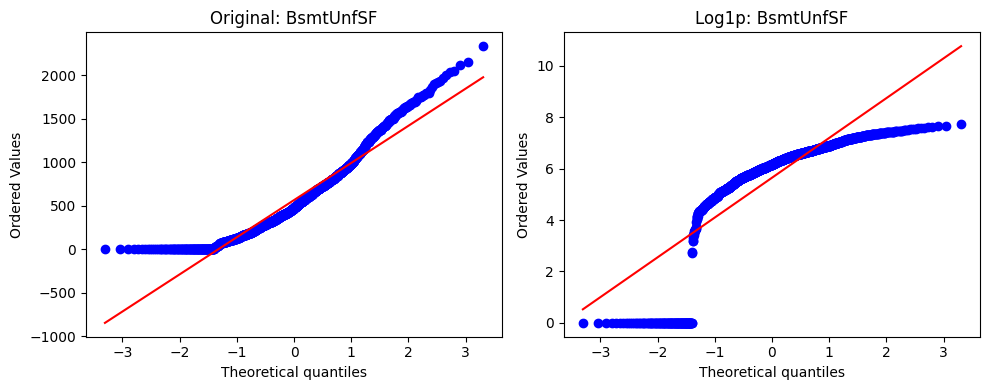

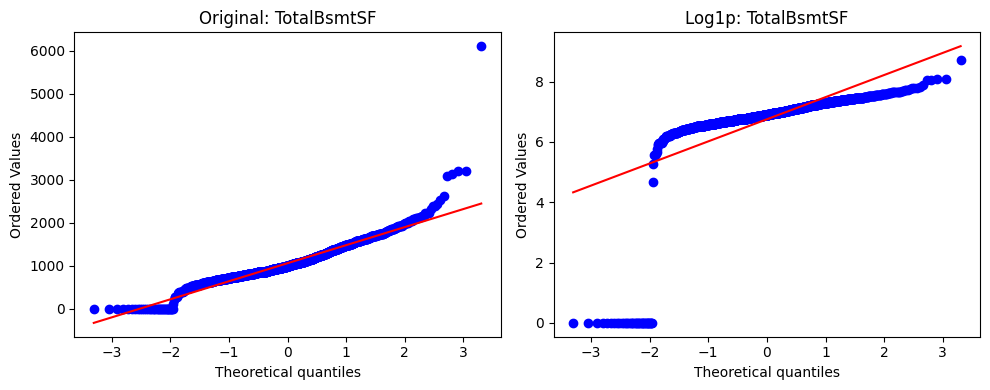

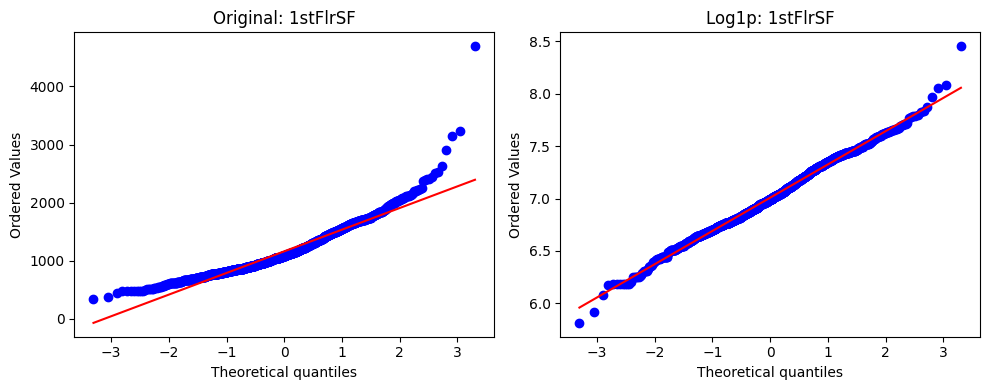

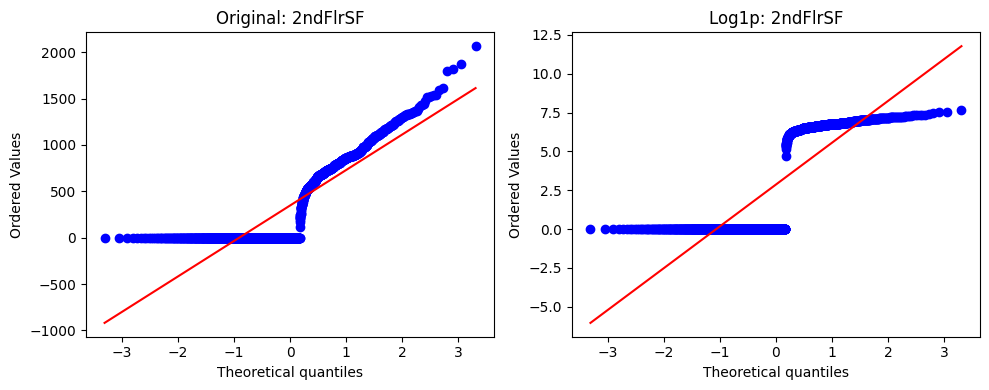

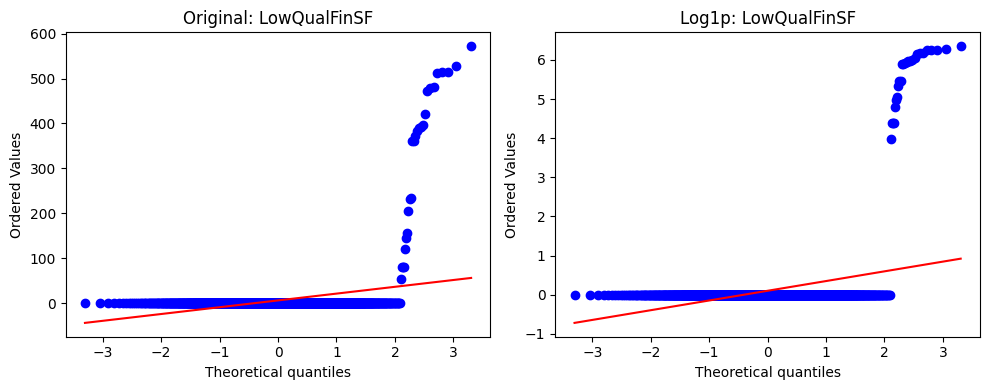

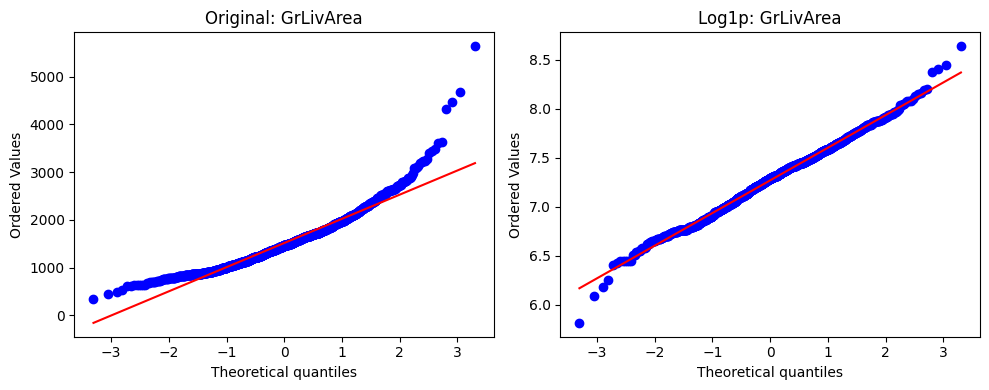

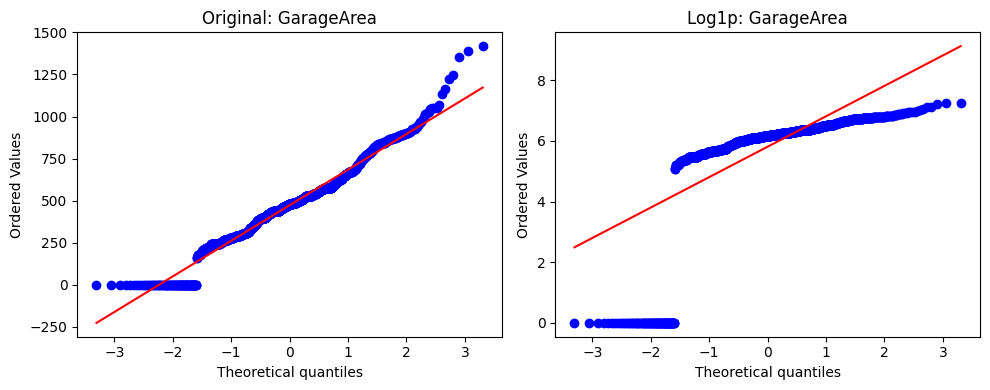

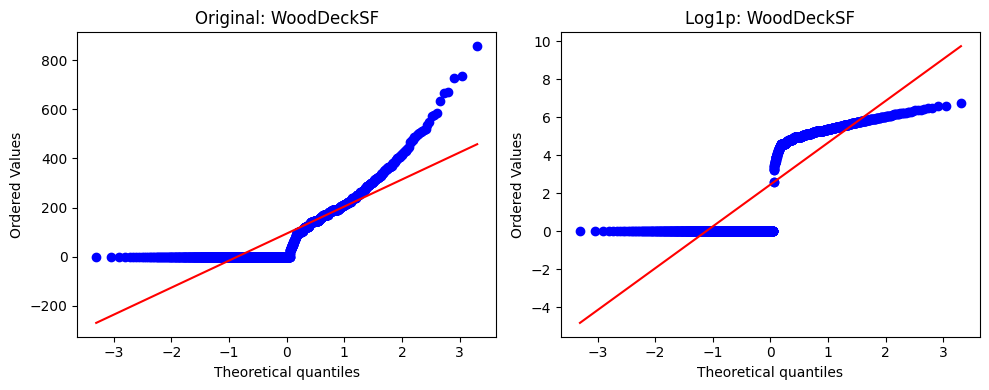

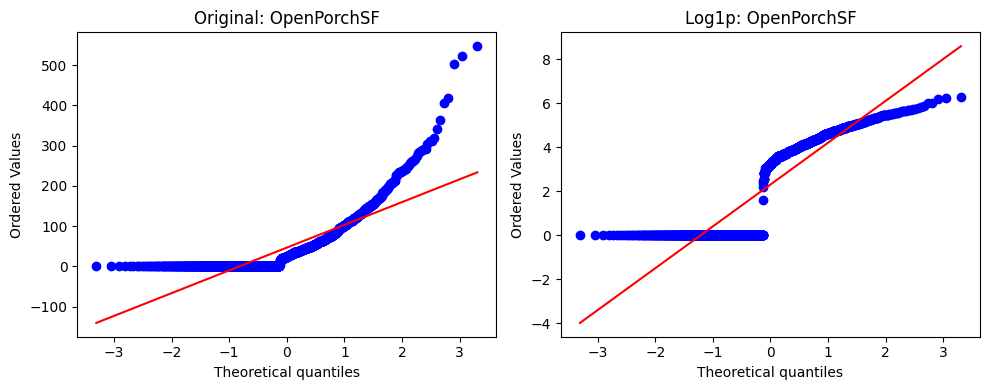

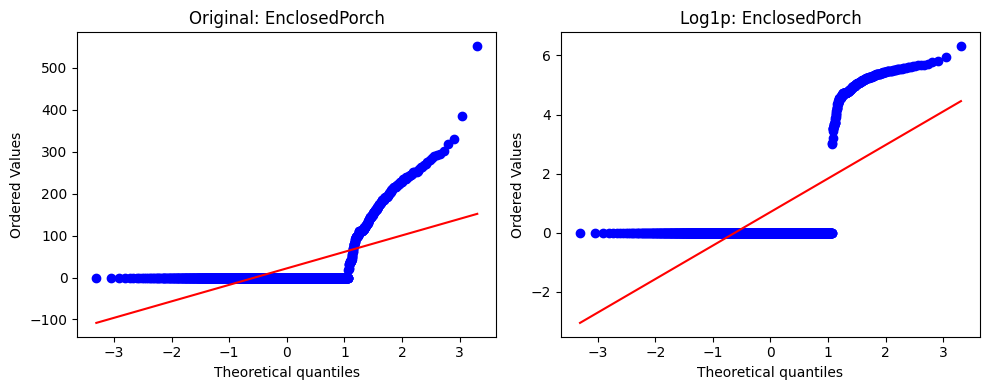

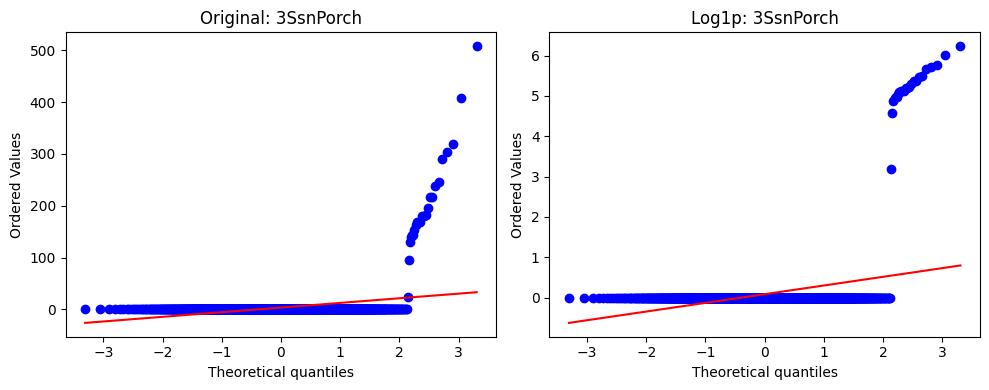

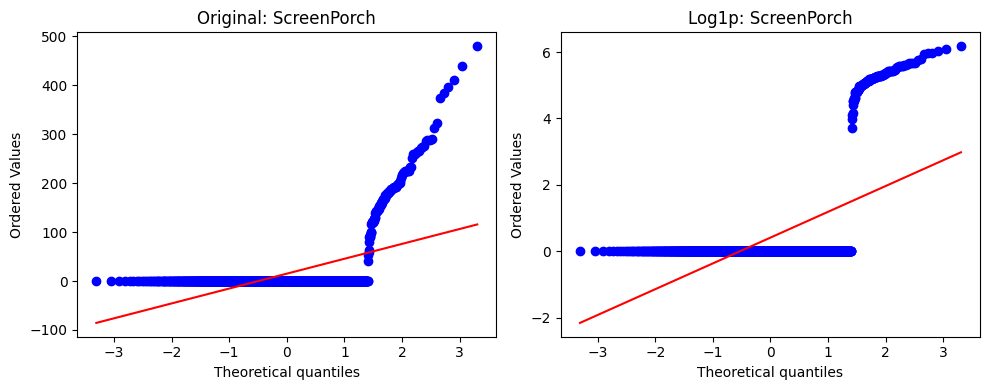

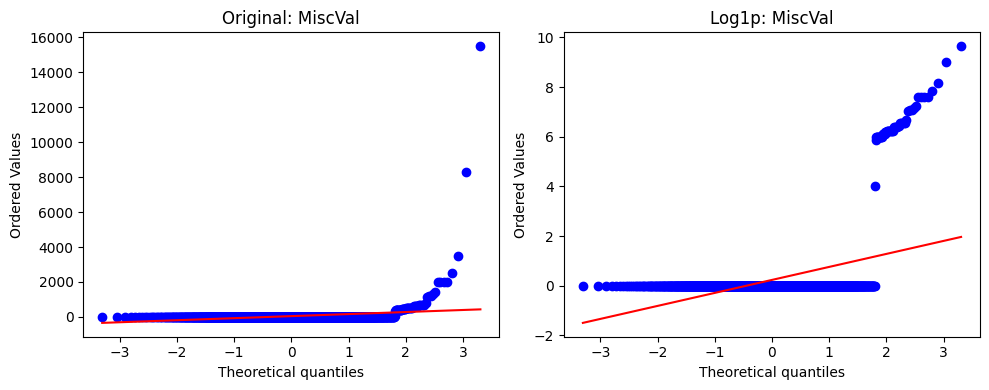

In [20]:
for var in cont_vars:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    original = df[var].dropna()
    transformed = np.log1p(original)

    stats.probplot(original, dist="norm", plot=axes[0])
    axes[0].set_title(f"Original: {var}")

    stats.probplot(transformed, dist="norm", plot=axes[1])
    axes[1].set_title(f"Log1p: {var}")

    plt.tight_layout()
    plt.show()


The Q-Q plots confirm that the logarithmic transformation improves the distribution of some variables, bringing them closer to normality. However, several features still show noticeable deviations from the theoretical normal distribution.

Next, I will examine how these transformations affect the relationships between the features and the target variable (`SalePrice`).

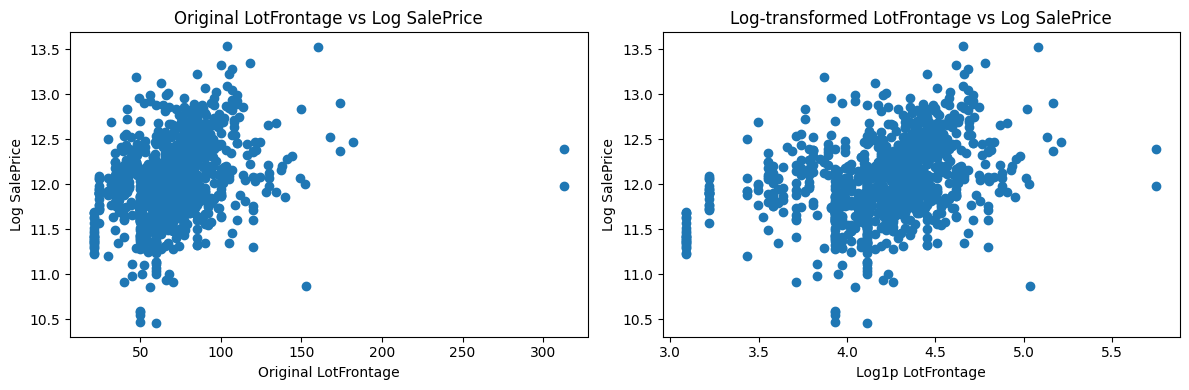

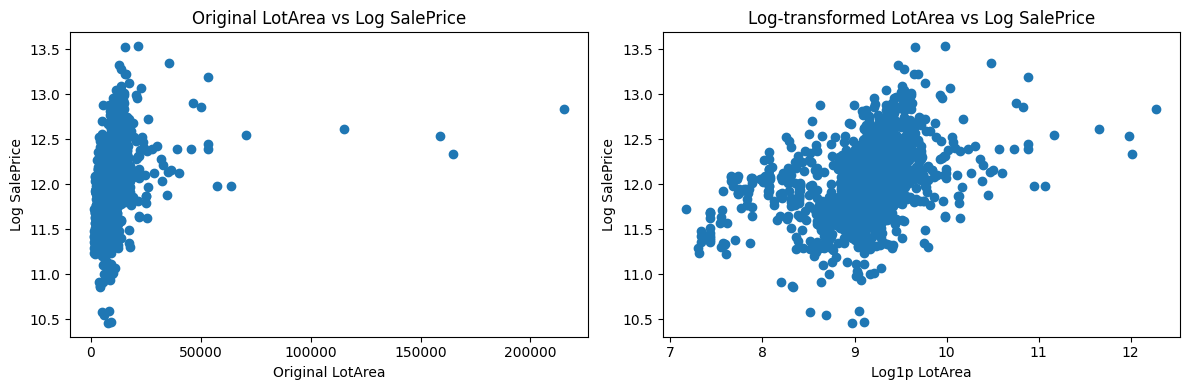

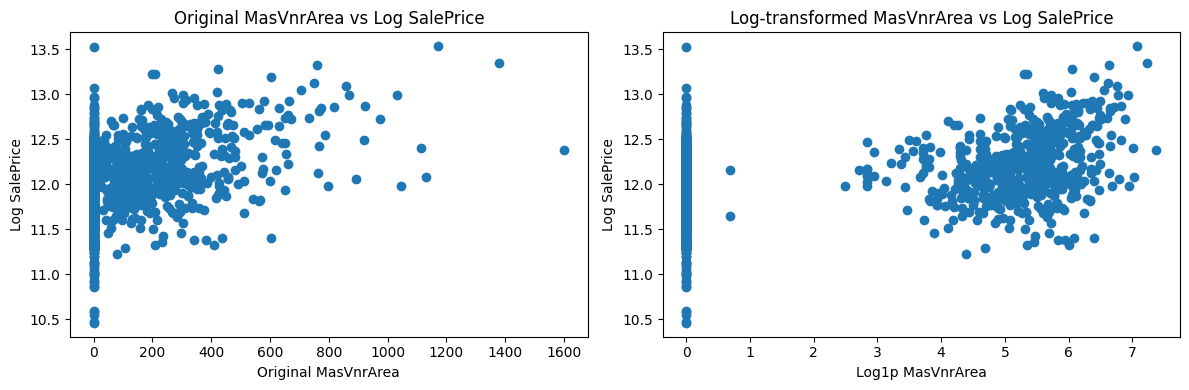

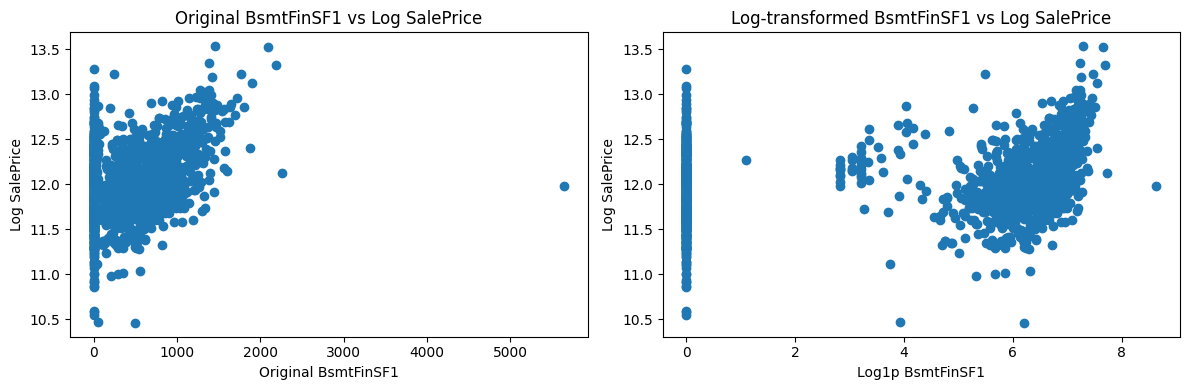

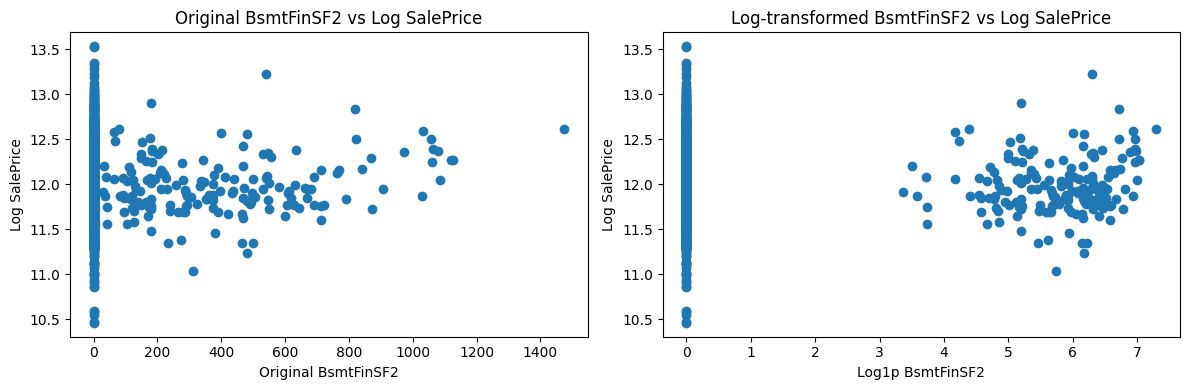

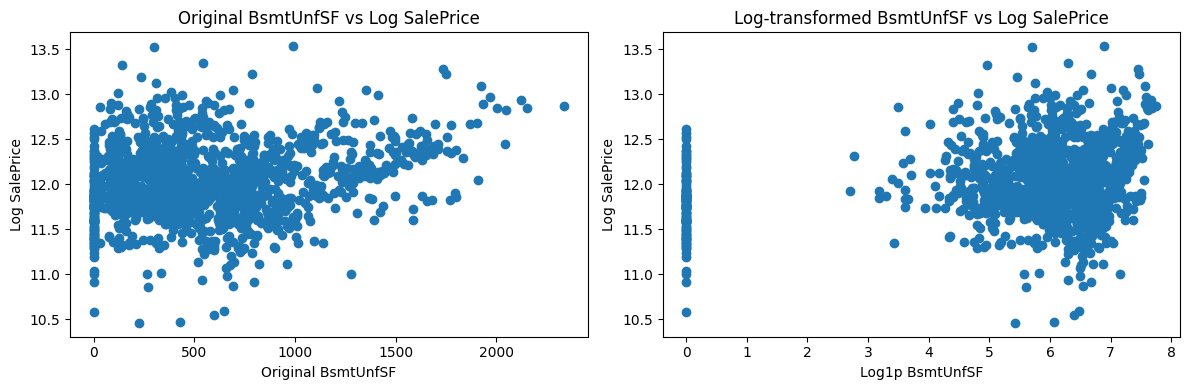

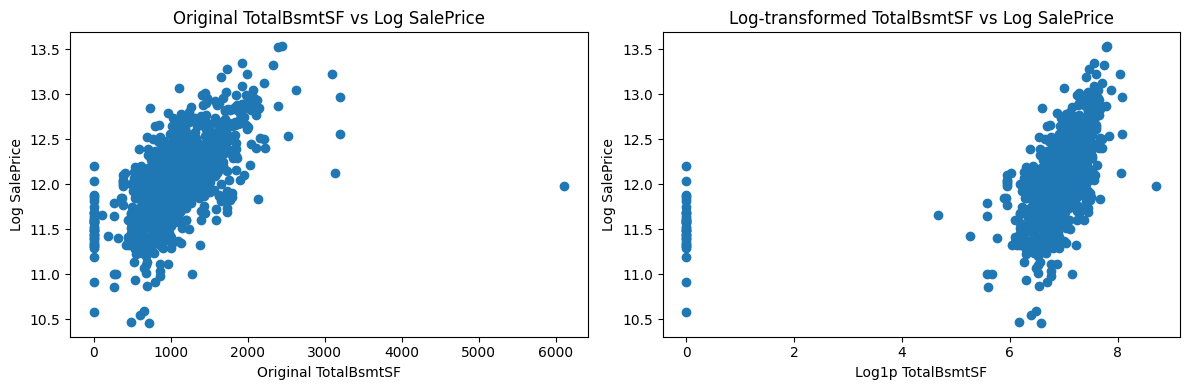

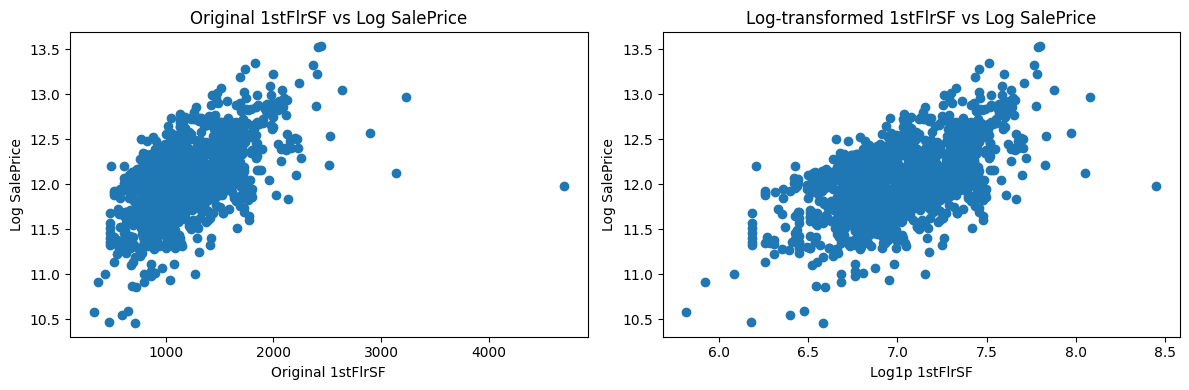

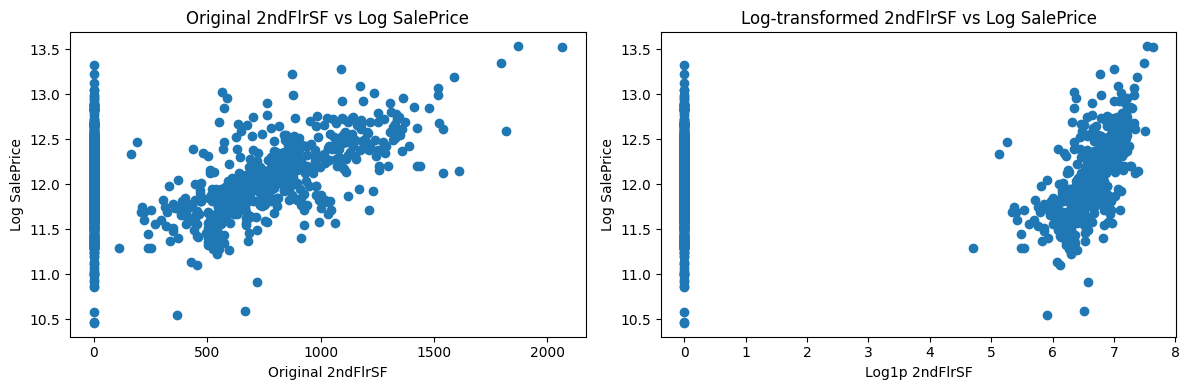

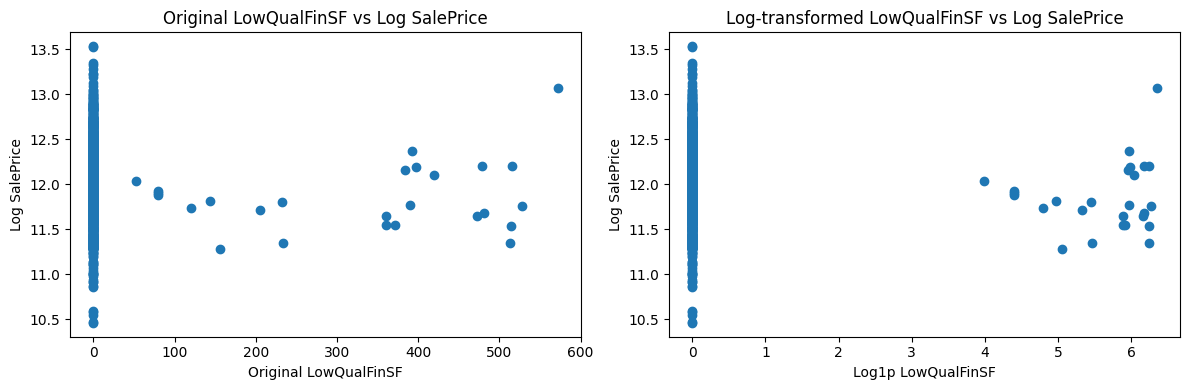

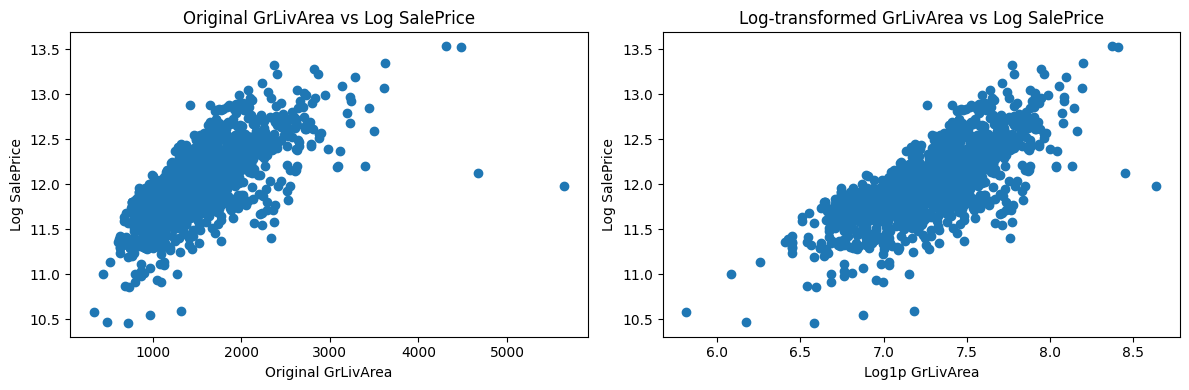

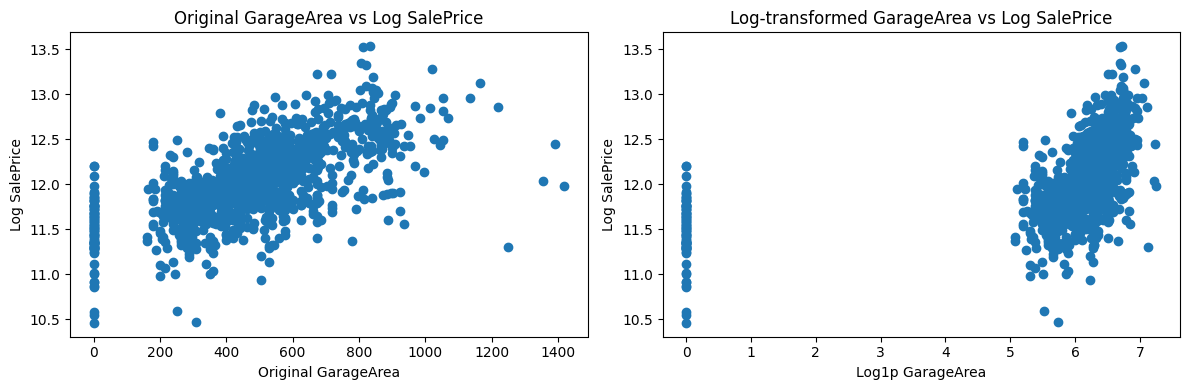

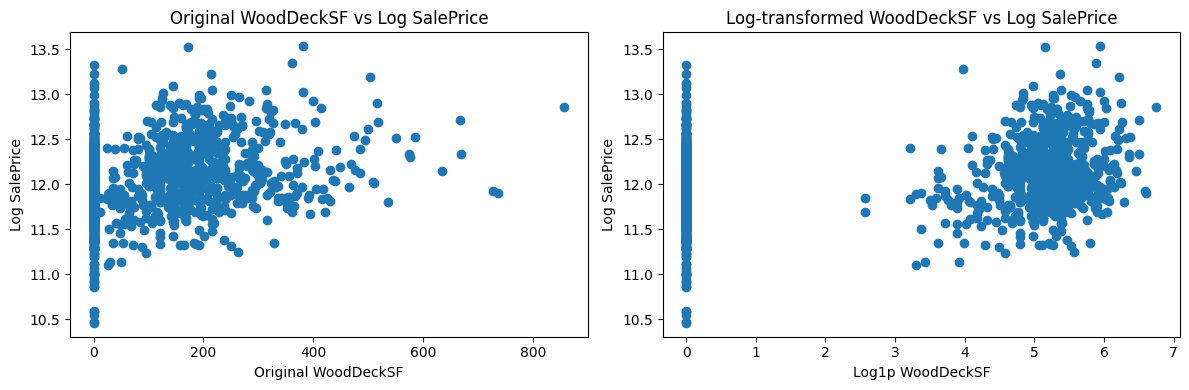

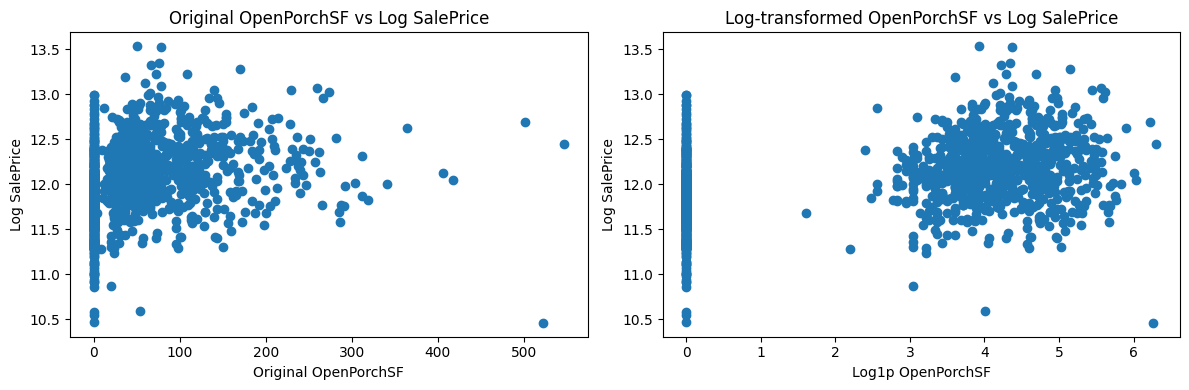

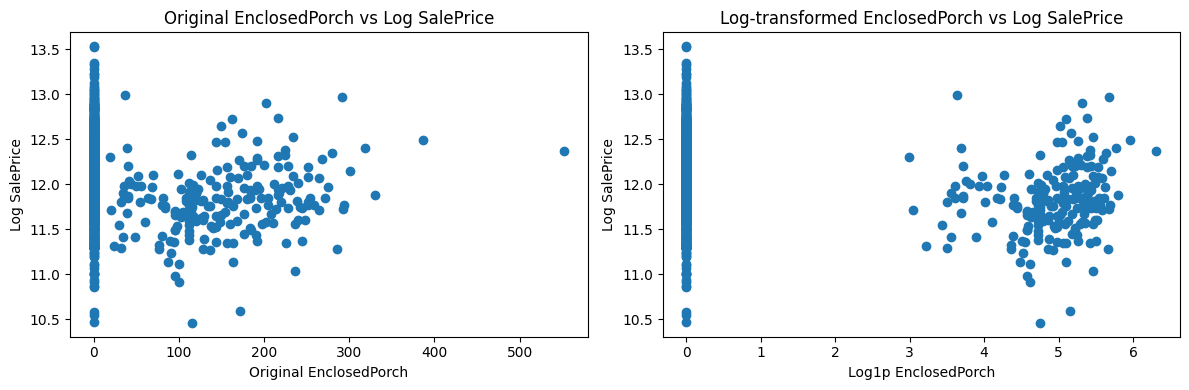

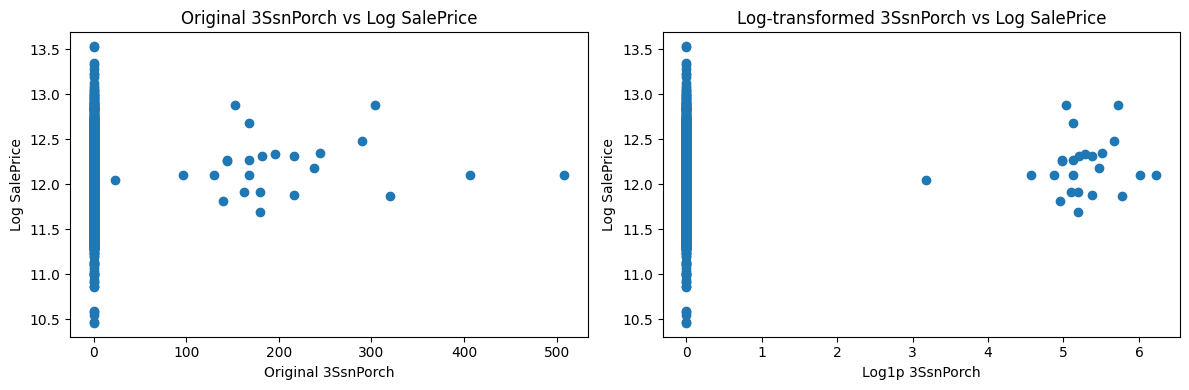

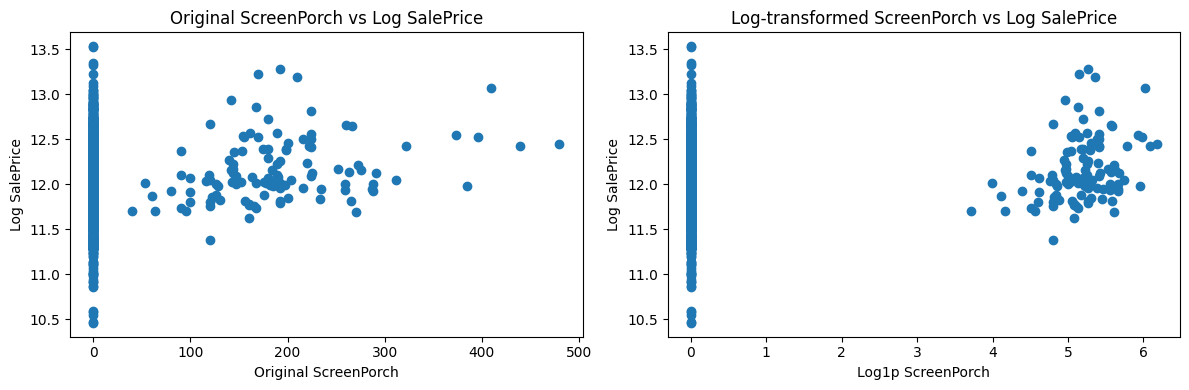

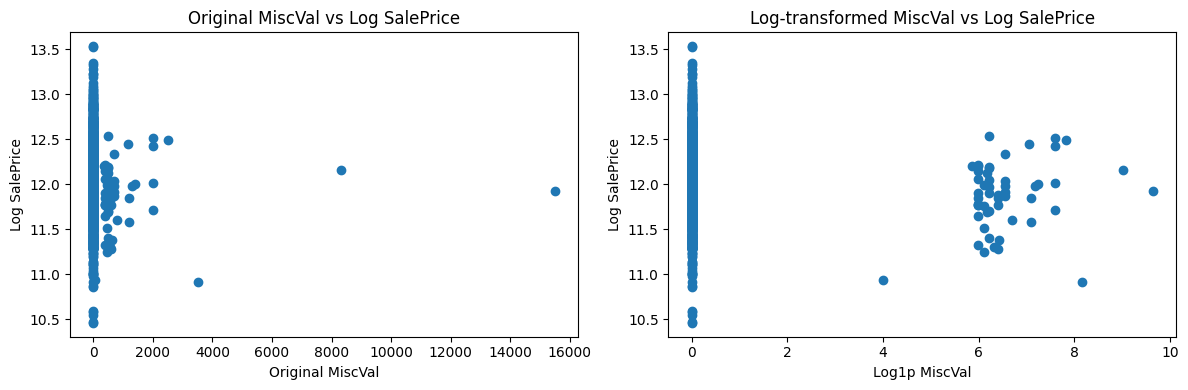

In [21]:
tmp = df.copy()

for var in cont_vars:
    tmp[var] = np.log1p(tmp[var])

for var in cont_vars:
    plt.figure(figsize=(12, 4))

    # Original feature
    plt.subplot(1, 2, 1)
    plt.scatter(df[var], np.log(df["SalePrice"]))
    plt.ylabel("Log SalePrice")
    plt.xlabel("Original " + var)
    plt.title(f"Original {var} vs Log SalePrice")

    # Log-transformed feature
    plt.subplot(1, 2, 2)
    plt.scatter(tmp[var], np.log(tmp["SalePrice"]))
    plt.ylabel("Log SalePrice")
    plt.xlabel("Log1p " + var)
    plt.title(f"Log-transformed {var} vs Log SalePrice")

    plt.tight_layout()
    plt.show()


Based on the distribution analysis and the relationships with the target variable, four features (`LotArea`, `LotFrontage`, `1stFlrSF`, and `GrLivArea`) appear to be promising candidates for logarithmic transformation.

The transformation improves the symmetry of their distributions and, in some cases, reveals a clearer relationship with `SalePrice`.

These transformations will be further evaluated and implemented, if beneficial, in the Feature Engineering stage.

## 6. Categorical Features Overview

In [29]:
cat_vars = [var for var in df.columns if df[var].dtypes=='O']
df[cat_vars].head()

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
1,RL,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
3,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,...,Detchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Abnorml
4,RL,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal


In [23]:
df[cat_vars].nunique().sort_values(ascending=False)

Neighborhood     25
Exterior2nd      16
Exterior1st      15
Condition1        9
SaleType          9
HouseStyle        8
RoofMatl          8
Condition2        8
Functional        7
BsmtFinType2      6
RoofStyle         6
BsmtFinType1      6
SaleCondition     6
Heating           6
Foundation        6
GarageType        6
ExterCond         5
LotConfig         5
MSZoning          5
GarageCond        5
GarageQual        5
HeatingQC         5
Electrical        5
BldgType          5
FireplaceQu       5
LandContour       4
LotShape          4
KitchenQual       4
MiscFeature       4
Fence             4
BsmtCond          4
ExterQual         4
BsmtExposure      4
BsmtQual          4
LandSlope         3
PoolQC            3
GarageFinish      3
PavedDrive        3
MasVnrType        3
Utilities         2
Alley             2
Street            2
CentralAir        2
dtype: int64

Some categorical variables have a natural order related to quality or condition. These ordinal features will be handled in the Feature Engineering notebook.

## 7. Key Findings

The exploratory data analysis revealed several important characteristics of the House Prices dataset that will guide the subsequent Feature Engineering and modeling stages.

**1. Target Variable Distribution**

The target variable (`SalePrice`) exhibits a right-skewed distribution. Applying a logarithmic transformation produces a more symmetric distribution, making it a promising approach for modeling house prices.

**2. Missing Values**

Several features contain missing values, with varying proportions across the dataset. For some variables, missingness appears to be associated with differences in average sale prices, suggesting that missing-value indicators may provide useful predictive information.

Appropriate imputation strategies and the potential value of missingness indicators will be investigated during Feature Engineering.

**3. Numerical Features**

Several numerical features, particularly `OverallQual` and `GrLivArea`, show strong relationships with the target variable.

Many continuous features exhibit right-skewed distributions, while others contain a large proportion of zero values. Logarithmic transformations improve the symmetry of some distributions, although they are not equally effective for every feature.

Based on the exploratory analysis, `LotArea`, `LotFrontage`, `1stFlrSF`, and `GrLivArea` are promising candidates for further evaluation of logarithmic transformations.

**4. Categorical Features**

Some categorical features represent ordinal information, particularly those describing property quality or condition. Their natural ordering should be considered when designing appropriate encoding strategies.

Other categorical features will require suitable encoding methods to make them usable by machine learning models.

**5. Feature Relationships and Redundancy**

The correlation analysis revealed strong relationships between selected numerical features and `SalePrice`, as well as potential redundancy among some predictors.

These observations motivate further investigation of feature selection and redundancy reduction during the modeling process.

### Next Steps

The findings from this analysis provide the foundation for the Feature Engineering stage, where missing-value handling, feature transformations, categorical encoding, and new feature creation will be explored.

The effectiveness of these approaches will subsequently be evaluated through cross-validation within the model training pipeline, helping to select transformations that improve predictive performance while avoiding data leakage.